<a href="https://colab.research.google.com/github/Narin-dlwlrma/Artificial-Intelligence-TP/blob/master/TP4_PHET_Narin_e20230091_I4_AMSB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



---


**Name:** Phet Narin

**Student ID:** e20230091

**Class:** I4-AMS-B

---




# TP4: Training with SGD, Mini-batches and Momentum

A typical training pipeline:
* Prepare the dataset: split it, normalize it to zero mean and unit variance.
* Define the model, the loss function and the optimizer; initialize the parameters.
* Loop until a stopping criterion:
  * take a mini-batch of data;
  * compute the forward pass;
  * compute the loss on the predictions and the labels;
  * update the parameters with the optimizer.
* Tune the hyperparameters: learning rate, batch size, number of epochs, optimizer.

PyTorch gives one object for each part (`DataLoader`, `nn.Module`, loss, `optim`), so we can change one part and keep the others.

**This TP**
1. **Follow along (Parts 0–4).** On a toy problem, train the same model three ways: SGD with **1 example per update**, **mini-batch** SGD, and mini-batch SGD with **momentum**. Then compare the three on one figure. Part 4 prepares MNIST for the exercises.
2. **Exercises (to submit).** On MNIST, and optionally CIFAR-10: experiment with the learning rate, the batch size, momentum and other optimizers, learning rate schedules and batch normalization. After each experiment, write what you observe and explain it in the cell.

**Runtime:** Colab with a GPU (Runtime → Change runtime type → T4 GPU).

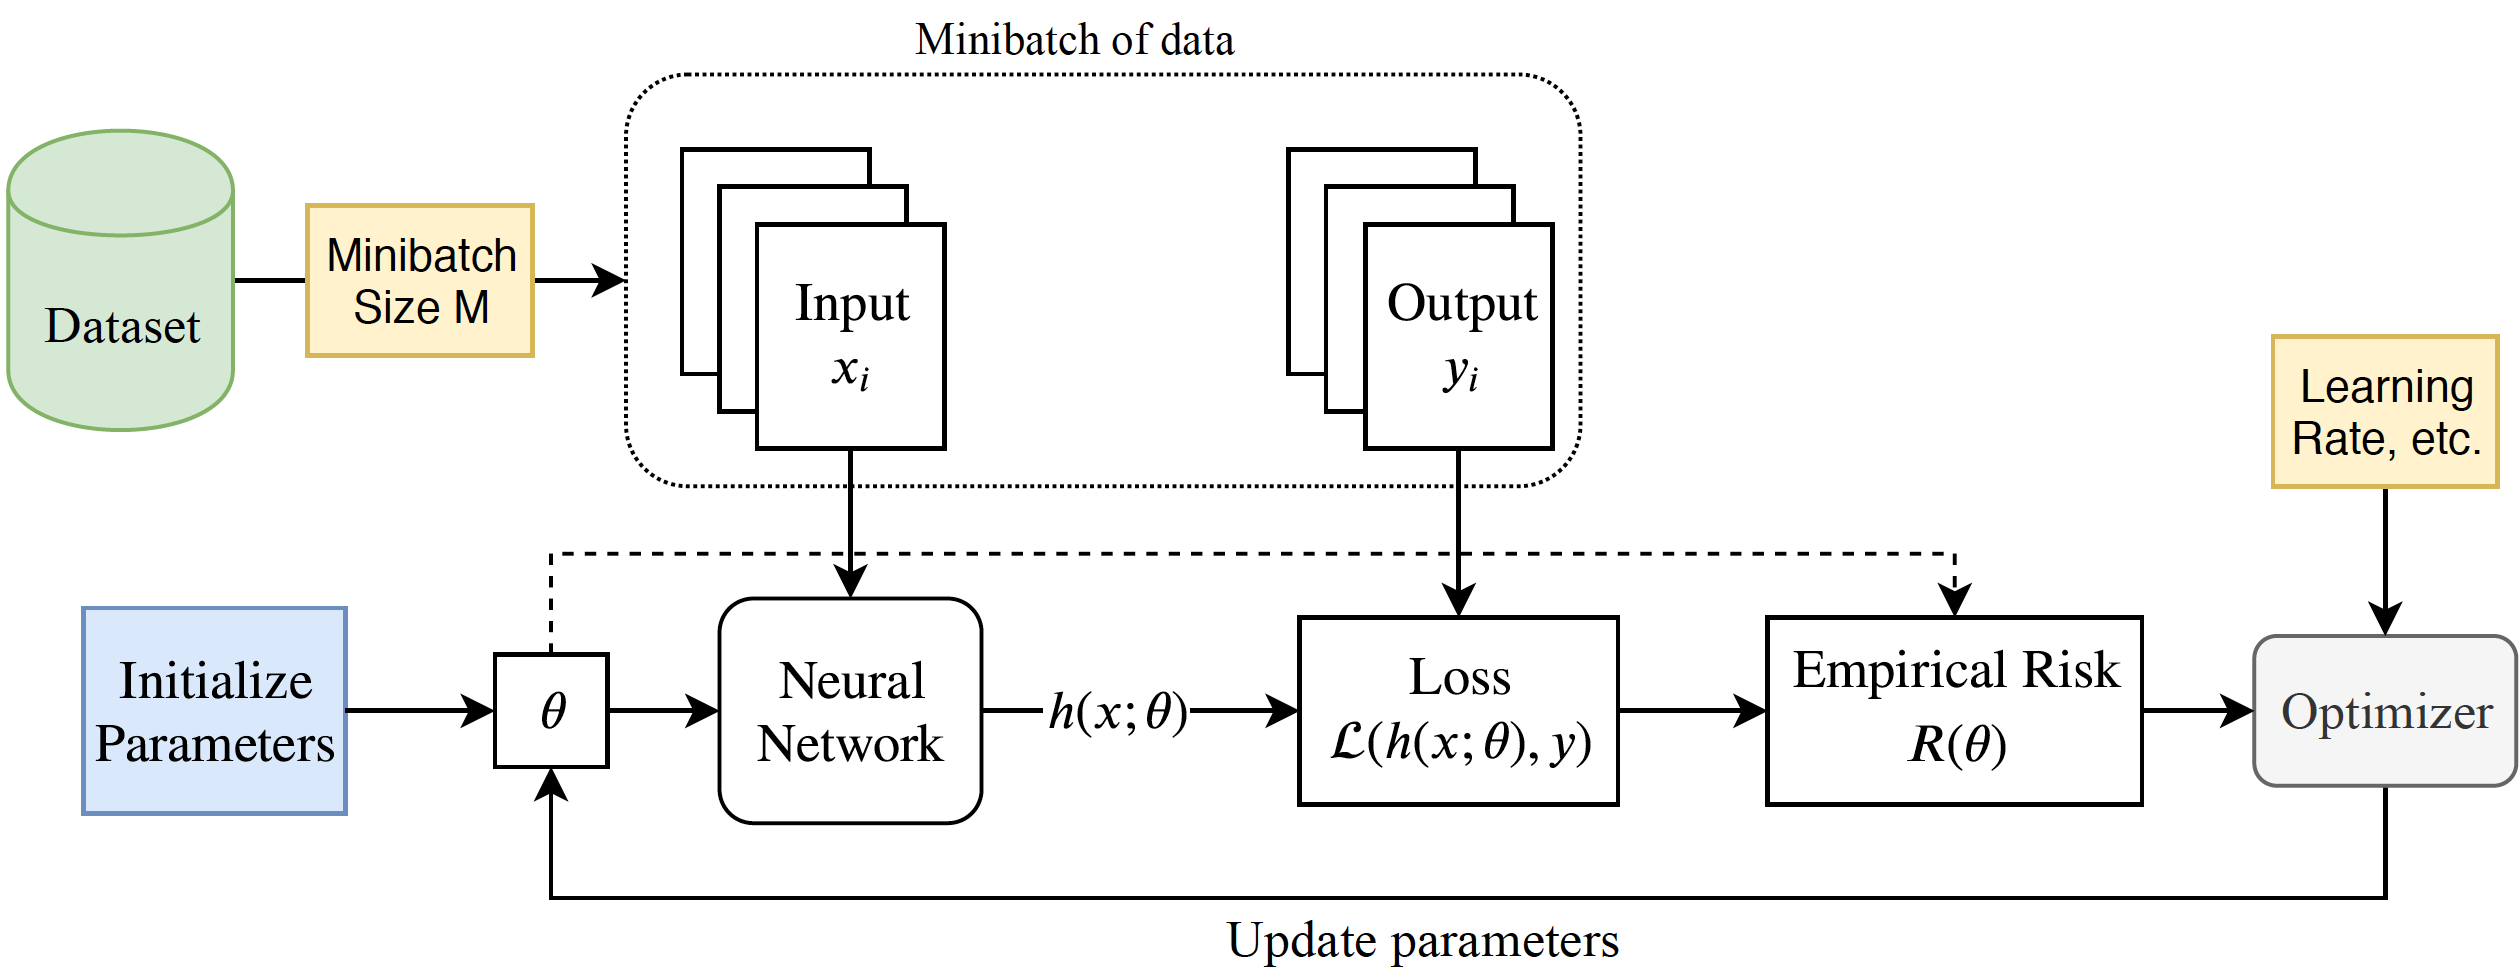

## 0 · Setup

In [ ]:
import math, time, random
import numpy as np
import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets
import matplotlib.pyplot as plt

SEED = 1234
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.14.1+cpu | device: cpu


## 1 · A toy problem: linear regression

1,000 points $(x, y)$ with $y = 3x + 2 + \text{noise}$ and $x$ between 0 and 5. The model is one linear unit, $\hat y = w x + b$ (`nn.Linear(1, 1)`), trained with the mean squared error
$$J(w, b) = \frac{1}{m}\sum_{i=1}^{m}\big(w x^{(i)} + b - y^{(i)}\big)^2 .$$
With only two parameters we can draw every step of the optimizer on the contour plot of $J$.

Inputs and targets are tensors of shape $(m, 1)$: one example per row.

least squares: w = 2.989, b = 2.062, J = 0.9493


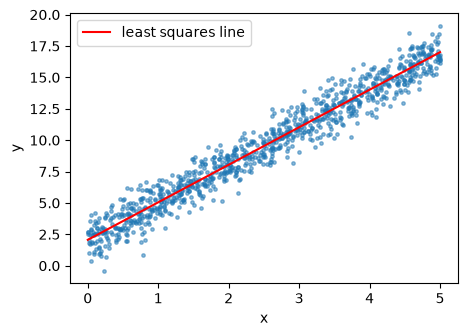

In [ ]:
m = 1000
gen = torch.Generator().manual_seed(0)
x_toy = 5 * torch.rand(m, 1, generator=gen)
y_toy = 3 * x_toy + 2 + torch.randn(m, 1, generator=gen)

# the best possible (w, b), by least squares, to measure how far each run is from it
A = torch.cat([x_toy, torch.ones(m, 1)], dim=1)
w_best, b_best = torch.linalg.lstsq(A, y_toy).solution.flatten().tolist()
J_best = ((w_best * x_toy + b_best - y_toy) ** 2).mean().item()
print(f"least squares: w = {w_best:.3f}, b = {b_best:.3f}, J = {J_best:.4f}")

plt.figure(figsize=(5, 3.5))
plt.scatter(x_toy, y_toy, s=6, alpha=0.5)
plt.plot([0, 5], [b_best, 5 * w_best + b_best], "r", label="least squares line")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()

Every run starts from the same point, $w = 0$, $b = 8$, uses the same learning rate $\alpha = 0.01$ and trains for 20 epochs. Only the **batch size** and **momentum** change.

`train_toy` is the PyTorch training loop. After every update it records:
- the loss $J(w, b)$ on **all** 1,000 points (to compare runs fairly, even when they update on different numbers of examples);
- the values of $w$ and $b$ (to draw the path).

In [ ]:
def full_loss(model):
    with torch.no_grad():
        return ((model(x_toy) - y_toy) ** 2).mean().item()

def train_toy(batch_size, lr=0.01, momentum=0.0, epochs=20, seed=0):
    model = nn.Linear(1, 1)
    with torch.no_grad():                              # same starting point for every run
        model.weight.fill_(0.0)
        model.bias.fill_(8.0)
    loss_fn = nn.MSELoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    loader = DataLoader(TensorDataset(x_toy, y_toy), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))

    hist = {"loss": [full_loss(model)], "w": [0.0], "b": [8.0], "epoch_loss": [full_loss(model)], "time": 0.0}
    for epoch in range(epochs):
        for x_t, y_t in loader:
            start = time.perf_counter()
            loss = loss_fn(model(x_t), y_t)            # forward pass and loss on the mini-batch
            optimizer.zero_grad()
            loss.backward()                            # backpropagation
            optimizer.step()                           # update w and b
            hist["time"] += time.perf_counter() - start
            hist["loss"].append(full_loss(model))      # record (not part of training)
            hist["w"].append(model.weight.item()); hist["b"].append(model.bias.item())
        hist["epoch_loss"].append(full_loss(model))
        if (epoch + 1) % 5 == 0:
            print(f"epoch {epoch + 1:2d} | J = {hist['epoch_loss'][-1]:.4f} | w = {model.weight.item():.3f}, b = {model.bias.item():.3f}")
    print(f"updates: {len(hist['loss']) - 1} | training time: {hist['time']:.2f} s")
    return hist

## 2 · Three ways to train

### 2.1 SGD with one example per update
`batch_size=1`: each update uses the gradient of **one** randomly chosen example. One epoch = 1,000 updates.

In [ ]:
hist_sgd = train_toy(batch_size=1)

epoch  5 | J = 0.9849 | w = 3.022, b = 2.163
epoch 10 | J = 0.9812 | w = 3.055, b = 2.048
epoch 15 | J = 1.0084 | w = 2.887, b = 2.127
epoch 20 | J = 0.9500 | w = 2.972, b = 2.112
updates: 20000 | training time: 12.81 s


The loss gets close to its minimum ($J \approx 1.05$, the noise level) within the first epoch, but then it **does not settle**: each update follows a single example, so $w$ and $b$ keep jumping around the minimum.

### 2.2 Mini-batch SGD
`batch_size=32`: each update uses the average gradient of 32 examples. One epoch = 32 updates (the last mini-batch has 8 examples).

In [ ]:
hist_mb = train_toy(batch_size=32)

epoch  5 | J = 3.1727 | w = 2.041, b = 4.983
epoch 10 | J = 1.4506 | w = 2.593, b = 3.461
epoch 15 | J = 1.0610 | w = 2.787, b = 2.724
epoch 20 | J = 0.9762 | w = 2.906, b = 2.381
updates: 640 | training time: 0.42 s


The updates are much less noisy, and each one is computed for 32 examples at once (vectorized). But with the same $\alpha$ there are 32 times fewer updates per epoch, so after 20 epochs the run is still on its way to the minimum.

### 2.3 Mini-batch SGD with momentum
Same mini-batches, with `momentum=0.9`. PyTorch’s update is
$$\mathbf{v} \leftarrow 0.9\,\mathbf{v} + \nabla J^{\{t\}}, \qquad \theta \leftarrow \theta - \alpha\,\mathbf{v}.$$

In [ ]:
hist_mom = train_toy(batch_size=32, momentum=0.9)

epoch  5 | J = 0.9845 | w = 2.942, b = 2.004
epoch 10 | J = 1.1423 | w = 3.120, b = 2.128
epoch 15 | J = 0.9601 | w = 3.024, b = 2.063
epoch 20 | J = 0.9495 | w = 2.997, b = 2.051
updates: 640 | training time: 0.47 s


## 3 · Comparing the three runs
Three views of the same three runs:
1. the loss after each **epoch** (above its minimum $J_{\text{best}}$, on a log scale);
2. the loss after each **update**;
3. the **path** of $(w, b)$ on the contours of $J$.

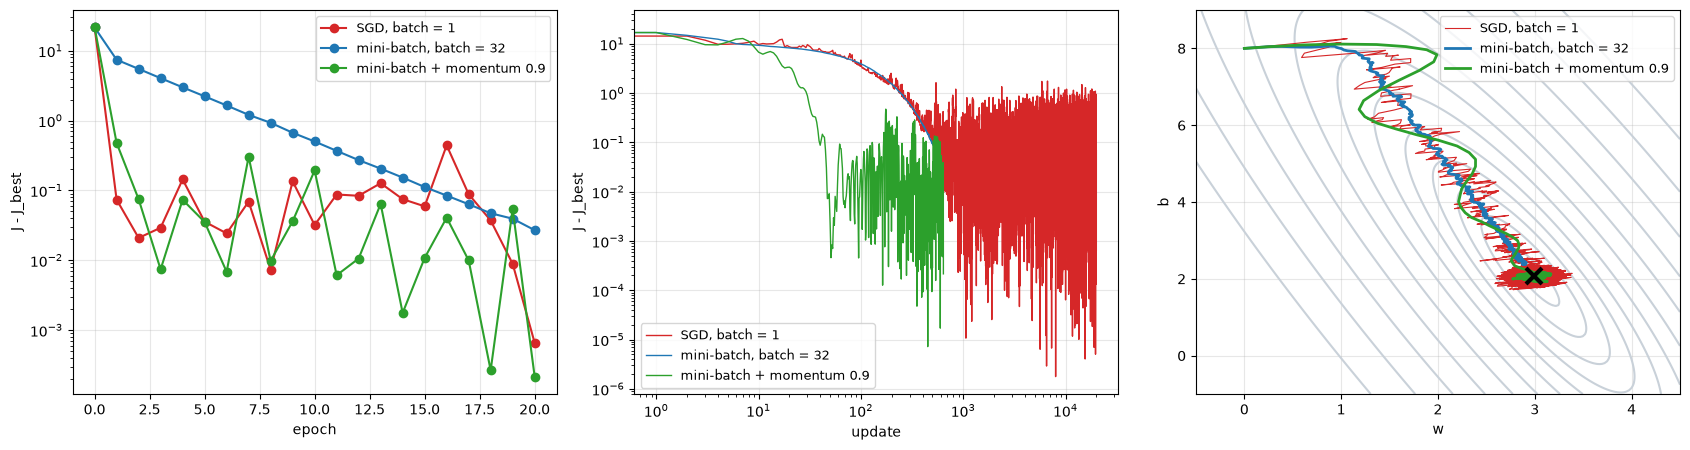

SGD, batch = 1               updates:  20000 | time: 12.81 s | final J - J_best: 0.0007
mini-batch, batch = 32       updates:    640 | time: 0.42 s | final J - J_best: 0.0269
mini-batch + momentum 0.9    updates:    640 | time: 0.47 s | final J - J_best: 0.0002


In [ ]:
runs = {"SGD, batch = 1": hist_sgd, "mini-batch, batch = 32": hist_mb, "mini-batch + momentum 0.9": hist_mom}
colors = ["tab:red", "tab:blue", "tab:green"]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for (label, h), c in zip(runs.items(), colors):
    ax[0].plot(np.array(h["epoch_loss"]) - J_best + 1e-6, "o-", color=c, label=label)
    ax[1].plot(np.array(h["loss"]) - J_best + 1e-6, color=c, lw=1, label=label)
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("J - J_best")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("update"); ax[1].set_ylabel("J - J_best")

W, B = torch.meshgrid(torch.linspace(-0.5, 4.5, 200), torch.linspace(-1, 9, 200), indexing="xy")
# J(w, b) on the grid, from the averages of x^2, x, xy, y, y^2 (expand the square)
Ex2, Ex, Exy, Ey, Ey2 = [t.mean().item() for t in (x_toy ** 2, x_toy, x_toy * y_toy, y_toy, y_toy ** 2)]
Jgrid = W ** 2 * Ex2 + 2 * W * B * Ex + B ** 2 - 2 * W * Exy - 2 * B * Ey + Ey2
ax[2].contour(W, B, Jgrid, levels=np.geomspace(1.1, 60, 12), colors="#C9D1D9")
for (label, h), c in zip(runs.items(), colors):
    ax[2].plot(h["w"], h["b"], color=c, lw=0.8 if "= 1" in label else 2, label=label)
ax[2].plot(w_best, b_best, "kx", ms=12, mew=3)
ax[2].set_xlabel("w"); ax[2].set_ylabel("b")
for a in ax:
    a.grid(alpha=0.3); a.legend(fontsize=9)
plt.tight_layout(); plt.show()

for label, h in runs.items():
    print(f"{label:28s} updates: {len(h['loss']) - 1:6d} | time: {h['time']:.2f} s | final J - J_best: {h['epoch_loss'][-1] - J_best:.4f}")

**What the figure shows**
- **SGD, batch = 1** (red): the most updates per epoch, so the fastest progress per epoch at first. Its path is a cloud of jumps: it reaches the minimum region quickly and then wanders around it. It also takes the most time: 1,000 small updates per epoch, one Python loop iteration each.
- **Mini-batch, batch = 32** (blue): a smooth path, with few updates per epoch. The contours are long, narrow ellipses (a **ravine**: $w$ and $b$ are strongly correlated because $x$ is not centered), and with $\alpha = 0.01$ the run moves slowly along the long direction.
- **Mini-batch + momentum** (green): the same number of updates as blue, but the velocity accumulates the steps along the ravine, so it reaches the minimum much sooner.

The run with batch = 1 would need a **decaying** learning rate to settle, and the run with batch = 32 a larger one or momentum: the batch size, the learning rate and momentum have to be chosen together. The exercises explore this on real data.

## 4 · Tools for the exercises: MNIST

### 4.1 The data
MNIST: 28 × 28 grayscale images of handwritten digits, 10 classes. We keep 54,000 images for training, 6,000 for validation, and the 10,000 test images for the very end. Each image is flattened to a row of 784 values and normalized with the mean and standard deviation of the training pixels. The tensors are prepared once, so the `DataLoader` is fast.

train (54000, 784) | val (6000, 784) | test (10000, 784)


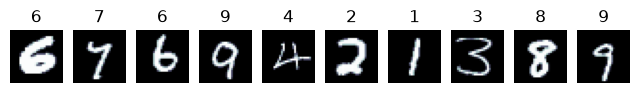

In [ ]:
train_full = datasets.MNIST(root="data", train=True, download=True)
test_full = datasets.MNIST(root="data", train=False, download=True)

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(42))
pixels = train_full.data[perm[:54000]].float() / 255
mean, std = pixels.mean(), pixels.std()                  # training statistics only

def prep(images):
    return ((images.float() / 255 - mean) / std).reshape(len(images), -1)   # (m, 784)

X_all, y_all = prep(train_full.data), train_full.targets
X_train, y_train = X_all[perm[:54000]], y_all[perm[:54000]]
X_val, y_val = X_all[perm[54000:]], y_all[perm[54000:]]
X_test, y_test = prep(test_full.data), test_full.targets
print("train", tuple(X_train.shape), "| val", tuple(X_val.shape), "| test", tuple(X_test.shape))

plt.figure(figsize=(8, 2.4))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="bone"); plt.title(int(y_train[i])); plt.axis("off")
plt.show()

def make_loader(batch_size=64, n_train=None, seed=0):
    # mini-batches of the first n_train training examples (all of them if n_train is None)
    X, y = (X_train, y_train) if n_train is None else (X_train[:n_train], y_train[:n_train])
    return DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True,
                      generator=torch.Generator().manual_seed(seed))

### 4.2 The model
A multilayer perceptron 784 → 128 → 100 → 10 with ReLU, returning logits. With `batch_norm=True`, an `nn.BatchNorm1d` layer comes after each hidden linear layer, before the ReLU, and the linear layer has no bias (batch norm’s $\beta$ replaces it). `make_model(seed)` gives the same initial weights for the same seed, so that two runs differ only by what you change.

In [ ]:
class MLP(nn.Module):
    def __init__(self, n_in=784, hidden=(128, 100), n_out=10, batch_norm=False):
        super().__init__()
        layers = []
        for h in hidden:
            layers.append(nn.Linear(n_in, h, bias=not batch_norm))
            if batch_norm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            n_in = h
        layers.append(nn.Linear(n_in, n_out))
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(x)

def make_model(seed=0, **kwargs):
    torch.manual_seed(seed)
    return MLP(**kwargs).to(device)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(make_model())
print(f"{count_parameters(make_model()):,} parameters | with batch norm: {count_parameters(make_model(batch_norm=True)):,}")

MLP(
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=100, bias=True)
    (3): ReLU()
    (4): Linear(in_features=100, out_features=10, bias=True)
  )
)
114,390 parameters | with batch norm: 114,618


### 4.3 Training and evaluation
- `evaluate(model, X, y)` returns the loss and the accuracy (%) on a dataset, in evaluation mode.
- `fit(model, optimizer, loader, epochs, scheduler=None)` trains with mini-batches and returns a history: the loss of every update (`"step_loss"`), and per epoch the training loss, the validation loss and accuracy, the learning rate and the elapsed time. If the loss becomes `nan` or `inf`, the run has **diverged**: `fit` stops and sets `"diverged"` to `True`. A scheduler, if given, is stepped once per epoch.
- `plot_history({label: history, ...})` plots the smoothed loss of every update and the validation accuracy per epoch.

In [ ]:
def evaluate(model, X, y, batch_size=2000):
    model.eval()
    loss_fn = nn.CrossEntropyLoss(reduction="sum")
    total, correct = 0.0, 0
    with torch.inference_mode():
        for i in range(0, len(X), batch_size):
            xb, yb = X[i:i + batch_size].to(device), y[i:i + batch_size].to(device)
            logits = model(xb)
            total += loss_fn(logits, yb).item()
            correct += (logits.argmax(dim=1) == yb).sum().item()
    return total / len(X), 100 * correct / len(X)

def fit(model, optimizer, loader, epochs, scheduler=None, verbose=True):
    loss_fn = nn.CrossEntropyLoss()
    hist = {"step_loss": [], "train_loss": [], "val_loss": [], "val_acc": [], "lr": [], "time": [], "diverged": False}
    start = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        hist["lr"].append(optimizer.param_groups[0]["lr"])
        total, count = 0.0, 0
        for X_t, y_t in loader:
            X_t, y_t = X_t.to(device), y_t.to(device)
            loss = loss_fn(model(X_t), y_t)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            hist["step_loss"].append(loss.item())
            total += loss.item() * len(y_t); count += len(y_t)
            if not math.isfinite(loss.item()):
                hist["diverged"] = True
                break
        if scheduler is not None:
            scheduler.step()
        val_loss, val_acc = evaluate(model, X_val, y_val)
        hist["train_loss"].append(total / count); hist["val_loss"].append(val_loss); hist["val_acc"].append(val_acc)
        hist["time"].append(time.perf_counter() - start)
        if verbose:
            print(f"epoch {epoch + 1:2d} | lr {hist['lr'][-1]:.2e} | train loss {total / count:.4f} | "
                  f"val loss {val_loss:.4f} | val acc {val_acc:.2f}% | {hist['time'][-1]:.1f} s")
        if hist["diverged"]:
            print("diverged (loss is nan or inf): stopping")
            break
    return hist

def smooth(values, beta=0.98):
    # exponentially weighted average with bias correction (Lecture 4)
    v, out = 0.0, []
    for t, x in enumerate(values, 1):
        x = x if math.isfinite(x) else 10.0
        v = beta * v + (1 - beta) * x
        out.append(v / (1 - beta ** t))
    return out

def plot_history(hists, title="", ylim=(0, 2.5)):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for label, h in hists.items():
        ax[0].plot(smooth(h["step_loss"]), label=label + (" (diverged)" if h["diverged"] else ""))
        ax[1].plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], "o-", label=label)
    ax[0].set_ylim(*ylim); ax[0].set_xlabel("update"); ax[0].set_ylabel("training loss (smoothed)")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation accuracy (%)")
    for a in ax:
        a.grid(alpha=0.3); a.legend(fontsize=9)
    fig.suptitle(title); plt.show()

### 4.4 Check that everything works
One run: Adam, $\alpha = 10^{-3}$, mini-batches of 64, 2 epochs on 10,000 training examples.

epoch  1 | lr 1.00e-03 | train loss 0.5883 | val loss 0.3269 | val acc 90.13% | 1.4 s
epoch  2 | lr 1.00e-03 | train loss 0.2570 | val loss 0.2603 | val acc 92.10% | 2.8 s
epoch  3 | lr 1.00e-03 | train loss 0.1828 | val loss 0.2301 | val acc 93.05% | 4.1 s


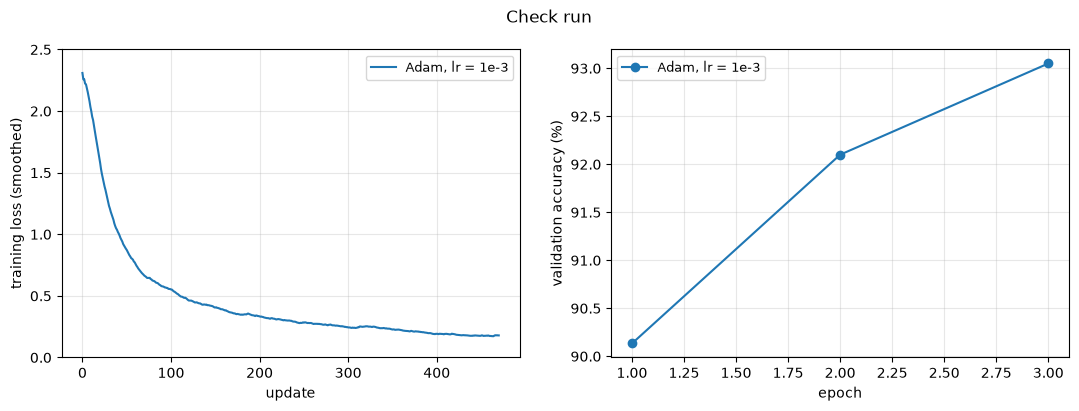

In [ ]:
model = make_model(seed=0)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
hist = fit(model, optimizer, make_loader(batch_size=64, n_train=10_000), epochs=3)
plot_history({"Adam, lr = 1e-3": hist}, "Check run")

---
## ★ Exercises (to submit)

**Rules for all exercises**
- Train on the first **10,000** training examples (`make_loader(..., n_train=10_000)`) for **5 epochs**, unless the exercise says otherwise.
- Create every model with `make_model(seed=0)` (add `batch_norm=True` when asked), so that all runs start from the same weights.
- Use `fit`, `evaluate` and `plot_history` from Part 4. Choose everything on the **validation** set; use the test set only in Exercise 8.
- A run that diverges is a result too: report it.


### Exercise 1 · The learning rate of SGD
1. Train with `optim.SGD` (no momentum), batch size 64, for each $\alpha \in \{1, 0.3, 0.1, 0.03, 0.01, 0.001\}$.
2. Plot the six runs on one figure with `plot_history`.
3. Print the best validation accuracy of each run.

epoch  1 | lr 1.00e+00 | train loss nan | val loss nan | val acc 9.72% | 0.4 s
diverged (loss is nan or inf): stopping
epoch  1 | lr 3.00e-01 | train loss 0.6940 | val loss 0.3263 | val acc 90.67% | 1.0 s
epoch  2 | lr 3.00e-01 | train loss 0.2314 | val loss 0.3524 | val acc 89.68% | 2.0 s
epoch  3 | lr 3.00e-01 | train loss 0.1474 | val loss 0.2704 | val acc 92.18% | 2.8 s
epoch  4 | lr 3.00e-01 | train loss 0.1072 | val loss 1.6728 | val acc 77.85% | 3.9 s
epoch  5 | lr 3.00e-01 | train loss 0.1064 | val loss 0.2282 | val acc 93.27% | 4.9 s
epoch  1 | lr 1.00e-01 | train loss 0.7062 | val loss 0.3833 | val acc 88.55% | 1.0 s
epoch  2 | lr 1.00e-01 | train loss 0.2839 | val loss 0.3740 | val acc 88.03% | 2.0 s
epoch  3 | lr 1.00e-01 | train loss 0.2034 | val loss 0.2901 | val acc 91.38% | 2.9 s
epoch  4 | lr 1.00e-01 | train loss 0.1600 | val loss 0.2095 | val acc 93.62% | 3.8 s
epoch  5 | lr 1.00e-01 | train loss 0.1164 | val loss 0.3302 | val acc 90.50% | 4.8 s
epoch  1 | lr 3.00e-0

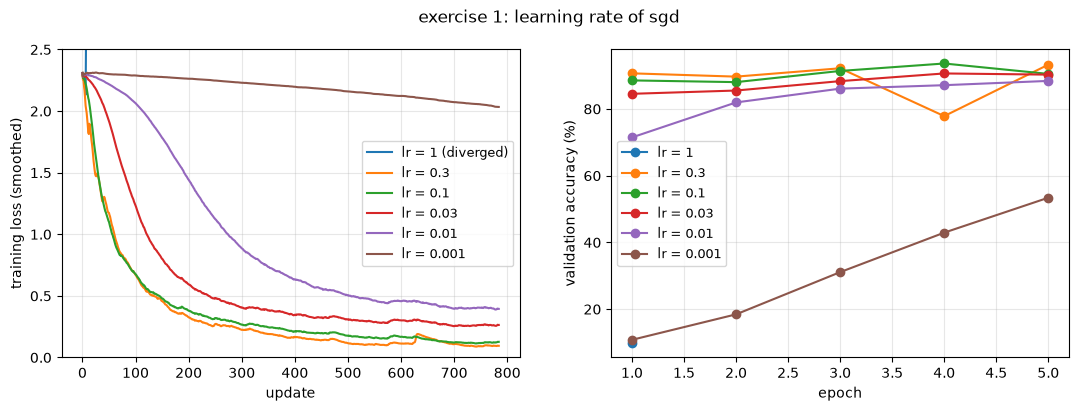

lr = 1: best validation accuracy = 9.72%
lr = 0.3: best validation accuracy = 93.27%
lr = 0.1: best validation accuracy = 93.62%
lr = 0.03: best validation accuracy = 90.63%
lr = 0.01: best validation accuracy = 88.40%
lr = 0.001: best validation accuracy = 53.40%


In [ ]:
# Exercise 1

learning_rates = [1, 0.3, 0.1, 0.03, 0.01, 0.001]

results = {}

for lr in learning_rates:
    model = make_model(seed=0)
    optimizer = optim.SGD(model.parameters(), lr=lr)
    loader = make_loader(batch_size=64, n_train=10_000)

    hist = fit(model, optimizer, loader, epochs=5)
    results[f"lr = {lr}"] = hist

# plot all runs
plot_history(results, "exercise 1: learning rate of sgd")

# print the best validation accuracy
for name, hist in results.items():
    best_acc = max(hist["val_acc"])
    print(f"{name}: best validation accuracy = {best_acc:.2f}%")


**Exercise 1: your observations and explanation.** *Write here.*


### observations and explanation

- lr = 1.0 is too large and causes the loss to become nan.
- lr = 0.3 and lr = 0.1 achieve the highest validation accuracy.
- lr = 0.1 gives the best validation accuracy of 93.62%.
- lr = 0.03 and lr = 0.01 learn more slowly and achieve lower accuracy.
- lr = 0.001 is too small, resulting in slow learning.

**conclusion:** the learning rate has a significant effect on training. a learning rate that is too large makes training unstable, while one that is too small makes learning slow. in this experiment, lr = 0.1 performs the best.


### Exercise 2 · Batch size: one example, mini-batches, the full set
1. Train with `optim.SGD`, $\alpha = 0.01$, for **3 epochs**, with batch sizes 1, 32, 256 and 10,000 (10,000 = batch gradient descent on this training set).
2. For each run, print the number of updates per epoch, the time per epoch and the best validation accuracy.
3. Plot the four runs.
4. Repeat steps 1–3 with $\alpha = 0.1$.


learning rate = 0.01
epoch  1 | lr 1.00e-02 | train loss 0.4416 | val loss 0.4109 | val acc 89.62% | 30.1 s
epoch  2 | lr 1.00e-02 | train loss 0.2115 | val loss 0.2225 | val acc 93.57% | 61.1 s
epoch  3 | lr 1.00e-02 | train loss 0.1410 | val loss 0.2359 | val acc 93.50% | 92.3 s
batch size = 1
updates per epoch = 10000
time per epoch = [30.15, 30.94, 31.22]
best validation accuracy = 93.57%
epoch  1 | lr 1.00e-02 | train loss 1.4694 | val loss 0.6934 | val acc 83.52% | 1.5 s
epoch  2 | lr 1.00e-02 | train loss 0.5182 | val loss 0.4488 | val acc 86.75% | 3.0 s
epoch  3 | lr 1.00e-02 | train loss 0.3849 | val loss 0.3840 | val acc 88.87% | 4.5 s
batch size = 32
updates per epoch = 313
time per epoch = [1.47, 1.5, 1.53]
best validation accuracy = 88.87%
epoch  1 | lr 1.00e-02 | train loss 2.2508 | val loss 2.1822 | val acc 25.18% | 0.5 s
epoch  2 | lr 1.00e-02 | train loss 2.1034 | val loss 2.0016 | val acc 51.67% | 1.1 s
epoch  3 | lr 1.00e-02 | train loss 1.8804 | val loss 1.7294 | v

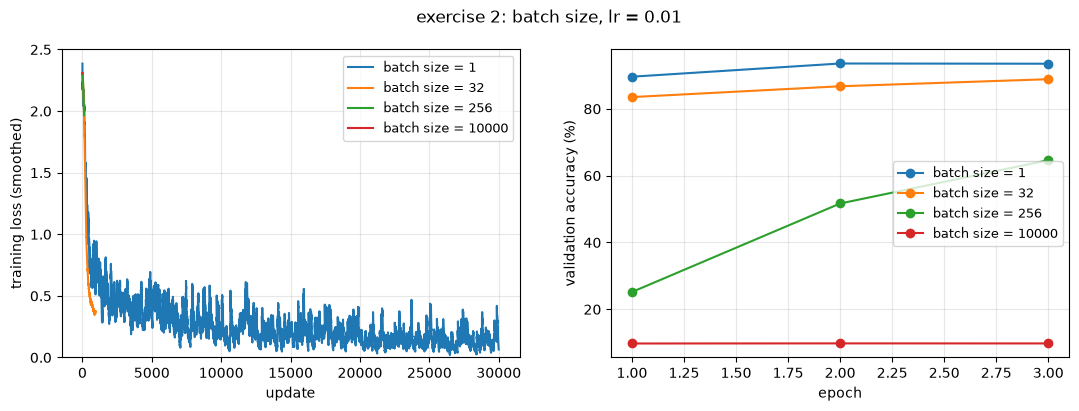


learning rate = 0.1
epoch  1 | lr 1.00e-01 | train loss 3.7754 | val loss 2.3349 | val acc 9.93% | 31.8 s
epoch  2 | lr 1.00e-01 | train loss 27.3604 | val loss 5.5083 | val acc 10.23% | 62.1 s
epoch  3 | lr 1.00e-01 | train loss 7734168.6185 | val loss 2.3231 | val acc 9.65% | 93.8 s
batch size = 1
updates per epoch = 10000
time per epoch = [31.76, 30.34, 31.74]
best validation accuracy = 10.23%
epoch  1 | lr 1.00e-01 | train loss 0.5535 | val loss 0.3337 | val acc 89.72% | 1.6 s
epoch  2 | lr 1.00e-01 | train loss 0.2262 | val loss 0.2587 | val acc 91.73% | 3.3 s
epoch  3 | lr 1.00e-01 | train loss 0.1440 | val loss 0.2135 | val acc 93.57% | 4.9 s
batch size = 32
updates per epoch = 313
time per epoch = [1.65, 1.65, 1.55]
best validation accuracy = 93.57%
epoch  1 | lr 1.00e-01 | train loss 1.3641 | val loss 0.8300 | val acc 72.13% | 0.6 s
epoch  2 | lr 1.00e-01 | train loss 0.5005 | val loss 0.9598 | val acc 67.43% | 1.1 s
epoch  3 | lr 1.00e-01 | train loss 0.3926 | val loss 0.777

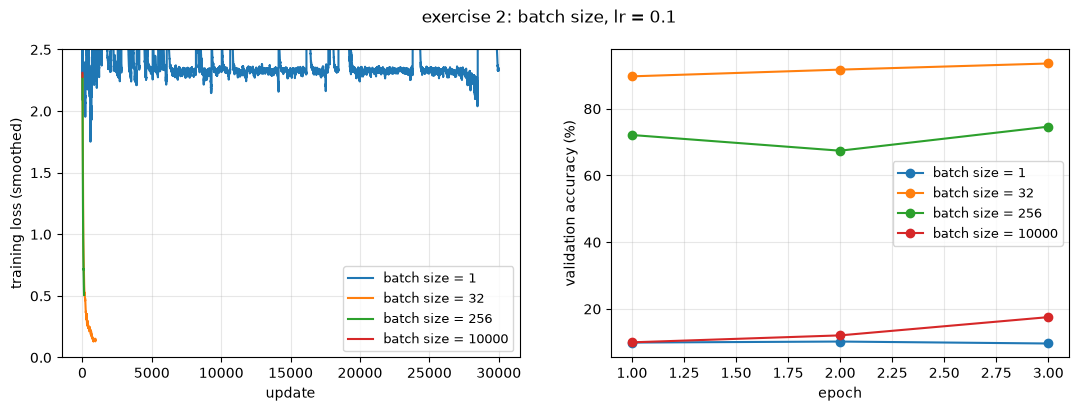

In [ ]:
# Exercise 2

batch_sizes = [1, 32, 256, 10000]
learning_rates = [0.01, 0.1]

for lr in learning_rates:
    results = {}

    print(f"\nlearning rate = {lr}")

    for bs in batch_sizes:
        model = make_model(seed=0)
        optimizer = optim.SGD(model.parameters(), lr=lr)
        loader = make_loader(batch_size=bs, n_train=10_000)

        hist = fit(model, optimizer, loader, epochs=3)

        results[f"batch size = {bs}"] = hist

        # calculate updates and time per epoch
        updates = math.ceil(10_000 / bs)
        times = [
            hist["time"][0]
        ] + [
            hist["time"][i] - hist["time"][i - 1]
            for i in range(1, len(hist["time"]))
        ]

        best_acc = max(hist["val_acc"])

        print(f"batch size = {bs}")
        print(f"updates per epoch = {updates}")
        print(f"time per epoch = {[round(t, 2) for t in times]}")
        print(f"best validation accuracy = {best_acc:.2f}%")

    # plot the four runs
    plot_history(results, f"exercise 2: batch size, lr = {lr}")


**Exercise 2: your observations and explanation.** *Write here.*

### observations and explanation

- batch size 1 gives the highest accuracy with lr = 0.01, but takes the longest training time.
- batch size 32 gives good accuracy with both learning rates and trains much faster.
- batch size 256 is faster but achieves lower accuracy after 3 epochs.
- batch size 10000 has only 1 update per epoch, so the model learns very slowly.
- with lr = 0.1, batch size 1 becomes unstable and gives very low accuracy.
- increasing the learning rate helps batch size 32, but does not improve every batch size.

**conclusion:** batch size affects the number of updates, training time and model accuracy. batch size 32 provides a good balance between training speed and accuracy in this experiment.


### Exercise 3 · Momentum
1. With batch size 64 and $\alpha = 0.01$, train: `optim.SGD(p, lr)`, `optim.SGD(p, lr, momentum=0.9)` and `optim.SGD(p, lr, momentum=0.9, nesterov=True)`.
2. Train `optim.SGD(p, lr=0.001, momentum=0.9)` and compare it with plain SGD at $\alpha = 0.01$.
3. Train `optim.SGD(p, lr, momentum=0.99)` with $\alpha = 0.01$.
4. Plot all the runs on one figure.

epoch  1 | lr 1.00e-02 | train loss 1.9640 | val loss 1.4242 | val acc 71.47% | 0.9 s
epoch  2 | lr 1.00e-02 | train loss 0.9640 | val loss 0.6974 | val acc 81.95% | 1.9 s
epoch  3 | lr 1.00e-02 | train loss 0.5692 | val loss 0.5124 | val acc 86.08% | 2.9 s
epoch  4 | lr 1.00e-02 | train loss 0.4508 | val loss 0.4438 | val acc 87.12% | 3.9 s
epoch  5 | lr 1.00e-02 | train loss 0.3938 | val loss 0.4040 | val acc 88.40% | 4.9 s
epoch  1 | lr 1.00e-02 | train loss 0.8135 | val loss 0.3554 | val acc 89.23% | 1.1 s
epoch  2 | lr 1.00e-02 | train loss 0.2945 | val loss 0.2834 | val acc 91.58% | 2.2 s
epoch  3 | lr 1.00e-02 | train loss 0.2109 | val loss 0.2458 | val acc 92.42% | 3.2 s
epoch  4 | lr 1.00e-02 | train loss 0.1593 | val loss 0.2065 | val acc 93.95% | 4.3 s
epoch  5 | lr 1.00e-02 | train loss 0.1195 | val loss 0.2028 | val acc 93.93% | 5.4 s
epoch  1 | lr 1.00e-02 | train loss 0.7820 | val loss 0.3632 | val acc 88.67% | 1.0 s
epoch  2 | lr 1.00e-02 | train loss 0.2885 | val loss 

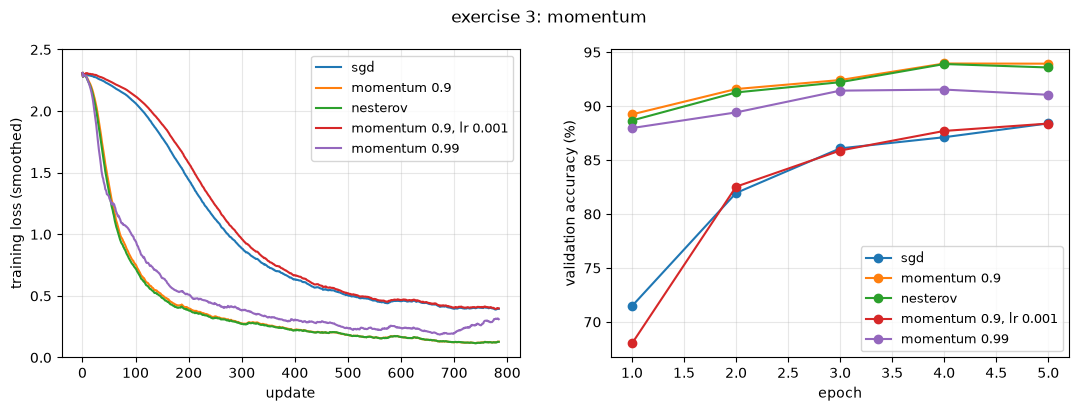

sgd: best validation accuracy = 88.40%
momentum 0.9: best validation accuracy = 93.95%
nesterov: best validation accuracy = 93.90%
momentum 0.9, lr 0.001: best validation accuracy = 88.38%
momentum 0.99: best validation accuracy = 91.53%


In [ ]:
# Exercise 3

results = {}

# normal sgd
model = make_model(seed=0)
optimizer = optim.SGD(model.parameters(), lr=0.01)
loader = make_loader(batch_size=64, n_train=10_000)
results["sgd"] = fit(model, optimizer, loader, epochs=5)

# sgd with momentum
model = make_model(seed=0)
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
loader = make_loader(batch_size=64, n_train=10_000)
results["momentum 0.9"] = fit(model, optimizer, loader, epochs=5)

# sgd with nesterov
model = make_model(seed=0)
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9, nesterov=True)
loader = make_loader(batch_size=64, n_train=10_000)
results["nesterov"] = fit(model, optimizer, loader, epochs=5)

# momentum with smaller learning rate
model = make_model(seed=0)
optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)
loader = make_loader(batch_size=64, n_train=10_000)
results["momentum 0.9, lr 0.001"] = fit(model, optimizer, loader, epochs=5)

# sgd with stronger momentum
model = make_model(seed=0)
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.99)
loader = make_loader(batch_size=64, n_train=10_000)
results["momentum 0.99"] = fit(model, optimizer, loader, epochs=5)

# plot all runs
plot_history(results, "exercise 3: momentum")

# print best validation accuracy
for name, hist in results.items():
    print(f"{name}: best validation accuracy = {max(hist['val_acc']):.2f}%")


**Exercise 3: your observations and explanation.** *Write here.*

### observations and explanation

- normal sgd achieves a best validation accuracy of 88.40%.
- momentum 0.9 improves the accuracy to 93.95%.
- nesterov achieves 93.90%, which is almost the same as momentum 0.9.
- using a smaller learning rate of 0.001 with momentum gives 88.38%, which is lower.
- momentum 0.99 achieves 91.53%, but performs worse than momentum 0.9.

**conclusion:** momentum helps sgd learn faster and achieve better accuracy by using previous updates. in this experiment, momentum 0.9 gives the best result, while nesterov performs almost equally well.


### Exercise 4 · Optimizers and their learning rates
1. For each optimizer below, train with $\alpha \in \{10^{-1}, 10^{-2}, 10^{-3}, 10^{-4}\}$, batch size 64:
   `optim.SGD`, `optim.SGD(momentum=0.9)`, `optim.Adagrad`, `optim.RMSprop`, `optim.Adam`, `optim.AdamW`.
2. Show a table of the best validation accuracy: one row per optimizer, one column per learning rate.
3. Plot the best run of each optimizer on one figure.

epoch  1 | lr 1.00e-01 | train loss 0.7062 | val loss 0.3833 | val acc 88.55% | 1.0 s
epoch  2 | lr 1.00e-01 | train loss 0.2839 | val loss 0.3740 | val acc 88.03% | 2.0 s
epoch  3 | lr 1.00e-01 | train loss 0.2034 | val loss 0.2901 | val acc 91.38% | 3.1 s
epoch  4 | lr 1.00e-01 | train loss 0.1600 | val loss 0.2095 | val acc 93.62% | 4.1 s
epoch  5 | lr 1.00e-01 | train loss 0.1164 | val loss 0.3302 | val acc 90.50% | 5.0 s
epoch  1 | lr 1.00e-02 | train loss 1.9640 | val loss 1.4242 | val acc 71.47% | 0.9 s
epoch  2 | lr 1.00e-02 | train loss 0.9640 | val loss 0.6974 | val acc 81.95% | 2.0 s
epoch  3 | lr 1.00e-02 | train loss 0.5692 | val loss 0.5124 | val acc 86.08% | 3.0 s
epoch  4 | lr 1.00e-02 | train loss 0.4508 | val loss 0.4438 | val acc 87.12% | 4.0 s
epoch  5 | lr 1.00e-02 | train loss 0.3938 | val loss 0.4040 | val acc 88.40% | 5.0 s
epoch  1 | lr 1.00e-03 | train loss 2.2858 | val loss 2.2613 | val acc 10.82% | 1.0 s
epoch  2 | lr 1.00e-03 | train loss 2.2369 | val loss 

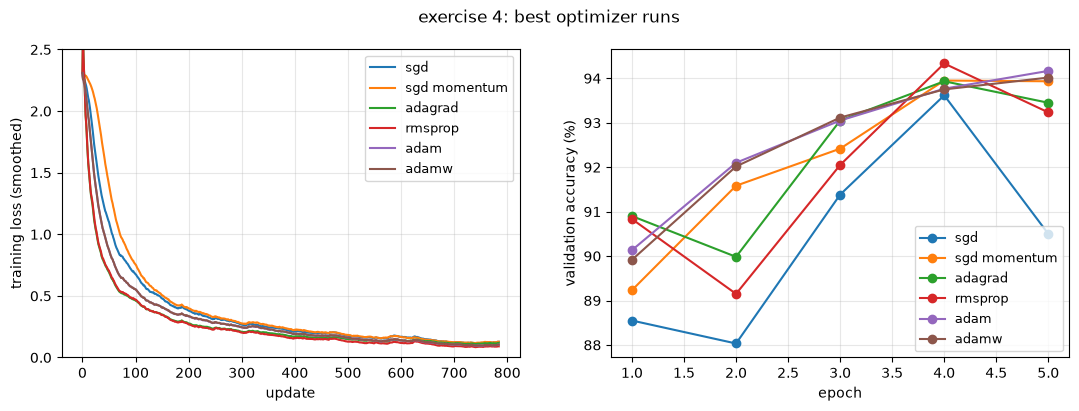

In [ ]:
# Exercise 4

learning_rates = [0.1, 0.01, 0.001, 0.0001]

optimizers = [
    ("sgd", optim.SGD, {}),
    ("sgd momentum", optim.SGD, {"momentum": 0.9}),
    ("adagrad", optim.Adagrad, {}),
    ("rmsprop", optim.RMSprop, {}),
    ("adam", optim.Adam, {}),
    ("adamw", optim.AdamW, {})
]

accuracy_table = {}
best_runs = {}

for name, optimizer_class, kwargs in optimizers:
    accuracy_table[name] = {}
    best_acc = 0

    for lr in learning_rates:
        model = make_model(seed=0)
        optimizer = optimizer_class(model.parameters(), lr=lr, **kwargs)
        loader = make_loader(batch_size=64, n_train=10_000)

        hist = fit(model, optimizer, loader, epochs=5)

        acc = max(hist["val_acc"])
        accuracy_table[name][lr] = acc

        if acc > best_acc:
            best_acc = acc
            best_runs[name] = hist

# print the accuracy table
print("\nbest validation accuracy (%)")
print(f"{'optimizer':<16}", end="")

for lr in learning_rates:
    print(f"{lr:<12}", end="")

print()

for name in accuracy_table:
    print(f"{name:<16}", end="")

    for lr in learning_rates:
        print(f"{accuracy_table[name][lr]:<12.2f}", end="")

    print()

# plot the best run of each optimizer
plot_history(best_runs, "exercise 4: best optimizer runs")


**Exercise 4: your observations and explanation.** *Write here.*

### observations and explanation

- sgd works best with lr = 0.1 and achieves 93.62%.
- sgd with momentum performs best with lr = 0.01, achieving 93.95%.
- adagrad also works best with lr = 0.01, achieving 93.93%.
- rmsprop gives the highest accuracy of 94.33% with lr = 0.001.
- adam and adamw also perform well with lr = 0.001.
- a learning rate that is too large can make some optimizers unstable.

**conclusion:** rmsprop gives the best result in this experiment, but adam and adamw also achieve similar accuracy. the best learning rate depends on the optimizer being used.



### Exercise 5 · Learning rate schedules
1. With `optim.SGD(p, lr=0.05, momentum=0.9)` and batch size 64, train for **10 epochs** with:
   - a constant learning rate;
   - `optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.3)`;
   - `optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.7)`;
   - `optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)`;
   - `optim.lr_scheduler.StepLR(optimizer, step_size=1, gamma=0.1)` (decays too early).
2. Plot the learning rate of each run per epoch (from `history["lr"]`), with a log scale on the y-axis.
3. Plot the five runs with `plot_history(..., ylim=(0, 0.8))`.

epoch  1 | lr 5.00e-02 | train loss 0.5629 | val loss 0.3021 | val acc 91.22% | 1.0 s
epoch  2 | lr 5.00e-02 | train loss 0.2163 | val loss 0.2398 | val acc 93.17% | 2.1 s
epoch  3 | lr 5.00e-02 | train loss 0.1553 | val loss 0.2648 | val acc 92.72% | 3.2 s
epoch  4 | lr 5.00e-02 | train loss 0.0988 | val loss 0.2047 | val acc 94.72% | 4.3 s
epoch  5 | lr 5.00e-02 | train loss 0.0703 | val loss 0.2301 | val acc 94.72% | 5.3 s
epoch  6 | lr 5.00e-02 | train loss 0.0625 | val loss 0.2381 | val acc 94.10% | 6.4 s
epoch  7 | lr 5.00e-02 | train loss 0.0436 | val loss 0.2381 | val acc 94.88% | 7.6 s
epoch  8 | lr 5.00e-02 | train loss 0.0373 | val loss 0.2853 | val acc 94.05% | 8.6 s
epoch  9 | lr 5.00e-02 | train loss 0.0358 | val loss 0.2445 | val acc 95.18% | 9.8 s
epoch 10 | lr 5.00e-02 | train loss 0.0345 | val loss 0.2615 | val acc 94.75% | 10.8 s
epoch  1 | lr 5.00e-02 | train loss 0.5629 | val loss 0.3021 | val acc 91.22% | 1.2 s
epoch  2 | lr 5.00e-02 | train loss 0.2163 | val loss

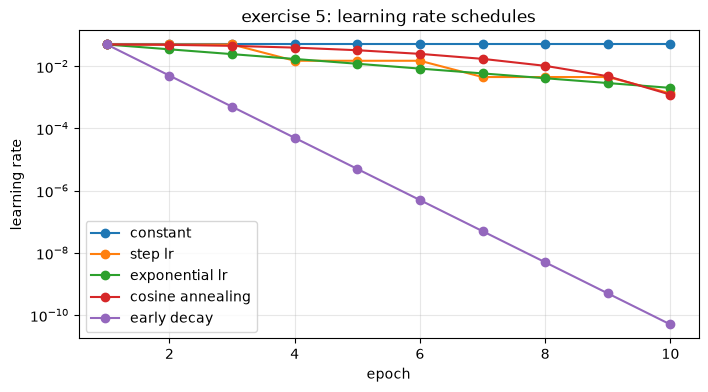

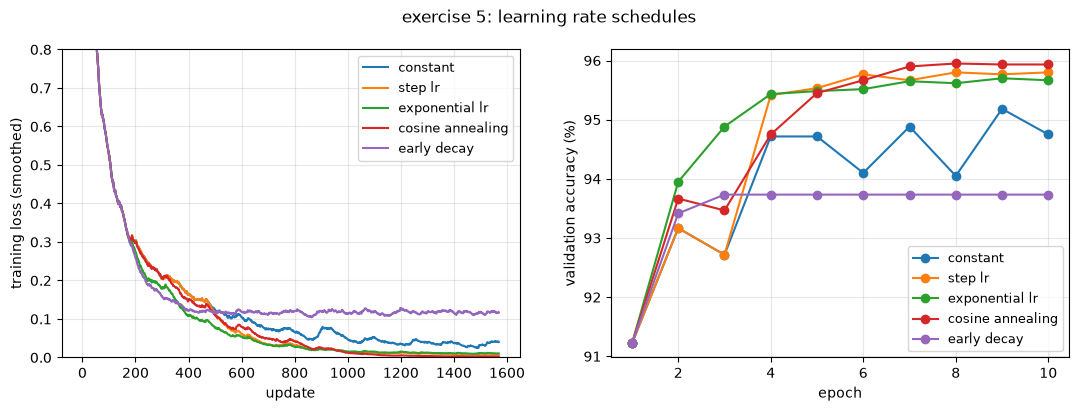

constant: best validation accuracy = 95.18%
step lr: best validation accuracy = 95.80%
exponential lr: best validation accuracy = 95.70%
cosine annealing: best validation accuracy = 95.95%
early decay: best validation accuracy = 93.73%


In [ ]:
# Exercise 5

results = {}

# constant learning rate
model = make_model(seed=0)
optimizer = optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
loader = make_loader(batch_size=64, n_train=10_000)
results["constant"] = fit(model, optimizer, loader, epochs=10)

# step learning rate
model = make_model(seed=0)
optimizer = optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.3)
loader = make_loader(batch_size=64, n_train=10_000)
results["step lr"] = fit(model, optimizer, loader, epochs=10, scheduler=scheduler)

# exponential learning rate
model = make_model(seed=0)
optimizer = optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
scheduler = optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.7)
loader = make_loader(batch_size=64, n_train=10_000)
results["exponential lr"] = fit(model, optimizer, loader, epochs=10, scheduler=scheduler)

# cosine annealing
model = make_model(seed=0)
optimizer = optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)
loader = make_loader(batch_size=64, n_train=10_000)
results["cosine annealing"] = fit(model, optimizer, loader, epochs=10, scheduler=scheduler)

# early decay
model = make_model(seed=0)
optimizer = optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=1, gamma=0.1)
loader = make_loader(batch_size=64, n_train=10_000)
results["early decay"] = fit(model, optimizer, loader, epochs=10, scheduler=scheduler)

# plot learning rate
plt.figure(figsize=(8, 4))

for name, hist in results.items():
    plt.plot(range(1, len(hist["lr"]) + 1), hist["lr"], "o-", label=name)

plt.yscale("log")
plt.xlabel("epoch")
plt.ylabel("learning rate")
plt.title("exercise 5: learning rate schedules")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# plot training results
plot_history(results, "exercise 5: learning rate schedules", ylim=(0, 0.8))

# print best validation accuracy
for name, hist in results.items():
    print(f"{name}: best validation accuracy = {max(hist['val_acc']):.2f}%")


**Exercise 5: your observations and explanation.** *Write here.*

### observations and explanation

- constant learning rate achieves 95.18% accuracy.
- steplr achieves 95.80% by reducing the learning rate every 3 epochs.
- exponentiallr achieves 95.70% by gradually reducing the learning rate.
- cosine annealing achieves the highest accuracy of 95.95%.
- early decay performs the worst with 93.73% because the learning rate decreases too quickly.

**conclusion:** learning rate schedules help improve training by adjusting the learning rate during training. cosine annealing gives the best result in this experiment, while early decay makes learning too slow.


### Exercise 6 · Batch normalization
1. For $\alpha \in \{1, 10^{-1}, 10^{-2}, 10^{-3}\}$, train `optim.SGD(p, lr, momentum=0.9)` with batch size 64, once **without** and once **with** batch norm (`make_model(seed=0, batch_norm=True)`).
2. Show a table of the best validation accuracy: rows = learning rates, columns = without / with batch norm.
3. Plot the eight runs.
4. Take your batch-norm model trained with $\alpha = 10^{-2}$. Evaluate it on the validation set in `model.eval()` mode (as `evaluate` does) and in `model.train()` mode with mini-batches of 8 examples, and compare the two accuracies.

epoch  1 | lr 1.00e+00 | train loss 893931288139638272.0000 | val loss 2772851935348201984.0000 | val acc 9.52% | 1.1 s
epoch  2 | lr 1.00e+00 | train loss nan | val loss nan | val acc 9.72% | 1.1 s
diverged (loss is nan or inf): stopping
epoch  1 | lr 1.00e+00 | train loss 0.7451 | val loss 0.6469 | val acc 83.98% | 1.3 s
epoch  2 | lr 1.00e+00 | train loss 0.5989 | val loss 0.7160 | val acc 81.62% | 2.6 s
epoch  3 | lr 1.00e+00 | train loss 0.6430 | val loss 0.5984 | val acc 88.77% | 3.8 s
epoch  4 | lr 1.00e+00 | train loss 0.5873 | val loss 0.4707 | val acc 89.32% | 5.0 s
epoch  5 | lr 1.00e+00 | train loss 0.8345 | val loss 1.0535 | val acc 78.57% | 6.2 s
epoch  1 | lr 1.00e-01 | train loss 0.6215 | val loss 0.4023 | val acc 89.68% | 1.0 s
epoch  2 | lr 1.00e-01 | train loss 0.3099 | val loss 0.3161 | val acc 91.42% | 2.1 s
epoch  3 | lr 1.00e-01 | train loss 0.2450 | val loss 0.3452 | val acc 91.98% | 3.1 s
epoch  4 | lr 1.00e-01 | train loss 0.2093 | val loss 0.3114 | val acc 92

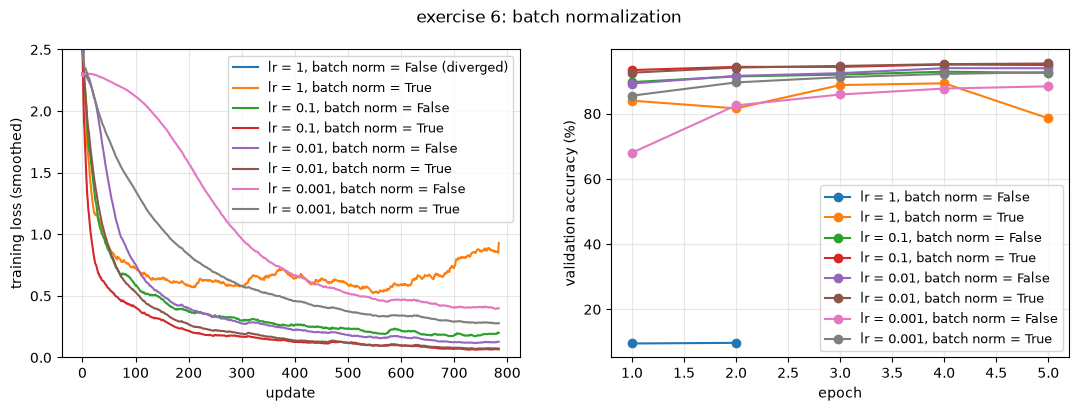


eval mode accuracy = 95.38%
train mode accuracy = 85.15%


In [ ]:
# Exercise 6

learning_rates = [1, 0.1, 0.01, 0.001]

results = {}
accuracy_table = {}

for lr in learning_rates:
    accuracy_table[lr] = {}

    for bn in [False, True]:
        model = make_model(seed=0, batch_norm=bn)
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
        loader = make_loader(batch_size=64, n_train=10_000)

        hist = fit(model, optimizer, loader, epochs=5)

        name = f"lr = {lr}, batch norm = {bn}"
        results[name] = hist

        best_acc = max(hist["val_acc"])
        accuracy_table[lr][bn] = best_acc

        # save the batch norm model with lr = 0.01
        if lr == 0.01 and bn:
            bn_model = model

# print accuracy table
print("\nbest validation accuracy (%)")
print(f"{'learning rate':<16} {'without bn':<15} {'with bn':<15}")

for lr in learning_rates:
    print(f"{lr:<16} {accuracy_table[lr][False]:<15.2f} {accuracy_table[lr][True]:<15.2f}")

# plot all eight runs
plot_history(results, "exercise 6: batch normalization")

# compare evaluation modes
bn_model.eval()
_, eval_acc = evaluate(bn_model, X_val, y_val)

bn_model.train()
correct = 0

with torch.no_grad():
    for i in range(0, len(X_val), 8):
        xb = X_val[i:i+8].to(device)
        yb = y_val[i:i+8].to(device)

        logits = bn_model(xb)
        correct += (logits.argmax(dim=1) == yb.to(device)).sum().item()

train_acc = 100 * correct / len(X_val)

print(f"\neval mode accuracy = {eval_acc:.2f}%")
print(f"train mode accuracy = {train_acc:.2f}%")


**Exercise 6: your observations and explanation.** *Write here.*


### observations and explanation

- batch normalization improves accuracy for all four learning rates.
- without batch normalization, lr = 1.0 causes the model to diverge.
- with batch normalization, lr = 1.0 achieves 89.32%.
- lr = 0.01 with batch normalization gives the highest accuracy of 95.38%.
- when evaluating the validation data in eval mode, accuracy is 95.38%.
- when evaluating the same data in train mode with batch size 8, accuracy drops to 85.15%.

**conclusion:** batch normalization helps make training more stable. eval mode gives better results because it uses the running statistics collected during training, while train mode uses statistics from each small batch.



### Exercise 7 · Your best model
1. Using what you learned in Exercises 1–6, choose an optimizer, a learning rate, a batch size, a schedule (or none), and with or without batch norm.
2. Train on the **full** training set (`n_train=None`) for 10 epochs.
3. Report the validation accuracy per epoch, and list your choices with one reason for each.

epoch  1 | lr 5.00e-02 | train loss 0.2577 | val loss 0.1606 | val acc 95.40% | 6.0 s
epoch  2 | lr 4.88e-02 | train loss 0.1118 | val loss 0.1212 | val acc 96.53% | 11.7 s
epoch  3 | lr 4.52e-02 | train loss 0.0797 | val loss 0.1166 | val acc 96.82% | 17.5 s
epoch  4 | lr 3.97e-02 | train loss 0.0556 | val loss 0.0970 | val acc 97.53% | 23.2 s
epoch  5 | lr 3.27e-02 | train loss 0.0352 | val loss 0.0945 | val acc 97.57% | 28.9 s
epoch  6 | lr 2.50e-02 | train loss 0.0162 | val loss 0.0828 | val acc 97.95% | 34.6 s
epoch  7 | lr 1.73e-02 | train loss 0.0080 | val loss 0.0885 | val acc 97.78% | 40.3 s
epoch  8 | lr 1.03e-02 | train loss 0.0042 | val loss 0.0827 | val acc 98.12% | 45.9 s
epoch  9 | lr 4.77e-03 | train loss 0.0028 | val loss 0.0842 | val acc 98.12% | 51.6 s
epoch 10 | lr 1.22e-03 | train loss 0.0024 | val loss 0.0845 | val acc 98.12% | 57.4 s

validation accuracy per epoch
epoch 1: 95.40%
epoch 2: 96.53%
epoch 3: 96.82%
epoch 4: 97.53%
epoch 5: 97.57%
epoch 6: 97.95%
epoc

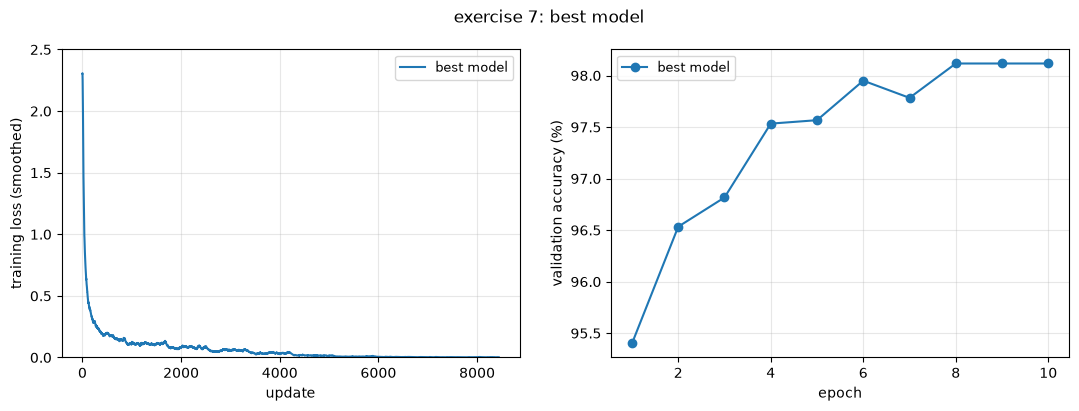

In [ ]:
# Exercise 7

# create the best model
model = make_model(seed=0)

# optimizer
optimizer = optim.SGD(model.parameters(), lr=0.05, momentum=0.9)

# learning rate schedule
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)

# use the full training set
loader = make_loader(batch_size=64, n_train=None)

# train for 10 epochs
hist = fit(model, optimizer, loader, epochs=10, scheduler=scheduler)

# print validation accuracy per epoch
print("\nvalidation accuracy per epoch")

for epoch, acc in enumerate(hist["val_acc"], 1):
    print(f"epoch {epoch}: {acc:.2f}%")

# print best validation accuracy
best_acc = max(hist["val_acc"])
print(f"\nbest validation accuracy = {best_acc:.2f}%")

# plot training results
plot_history({"best model": hist}, "exercise 7: best model")


**Exercise 7: your observations and explanation.** *Write here.*

### observations and explanation

- validation accuracy increases from 95.40% in epoch 1 to 98.12% in epoch 8.
- the accuracy stays at 98.12% during the last three epochs.
- training loss decreases from 0.2577 to 0.0024.
- cosine annealing gradually reduces the learning rate during training.

**my choices:**

- optimizer: sgd with momentum 0.9, because it performed better than normal sgd in exercise 3.
- learning rate: 0.05, because it was used successfully in exercise 5.
- batch size: 64, because it provides a good balance between training speed and accuracy.
- schedule: cosine annealing, because it achieved the highest validation accuracy in exercise 5.
- batch normalization: disabled, because I kept the configuration used for the learning-rate schedule experiments in exercise 5. exercise 6 showed that batch normalization can also improve accuracy.

**conclusion:** the model achieves 98.12% validation accuracy after training on the full training set for 10 epochs.



### Exercise 8 · Test accuracy
Evaluate your model of Exercise 7 on the test set, **once**, and report the test accuracy next to its best validation accuracy.

In [ ]:
# Exercise 8

# evaluate the model on the test set once
test_loss, test_acc = evaluate(model, X_test, y_test)

# get the best validation accuracy
best_val_acc = max(hist["val_acc"])

# print results
print(f"best validation accuracy = {best_val_acc:.2f}%")
print(f"test accuracy = {test_acc:.2f}%")
print(f"difference = {abs(best_val_acc - test_acc):.2f}%")


best validation accuracy = 98.12%
test accuracy = 98.31%
difference = 0.19%


**Exercise 8: your observations and explanation.** *Write here.*

### observations and explanation

- the best validation accuracy is 98.12%.
- the test accuracy is 98.31%.
- the difference between them is only 0.19%.
- the test accuracy is slightly higher than the validation accuracy.
- the model performs well on unseen test data.

**conclusion:** the model achieves 98.31% test accuracy, which is very close to its validation accuracy. this shows that the model generalizes well to unseen data.


### Exercise 9 (optional) · CIFAR-10
CIFAR-10: 32 × 32 color images, 10 classes (airplane, car, bird, …), 50,000 training and 10,000 test images.
1. Load it with `datasets.CIFAR10(root="data", train=True, download=True)`. The images are in `.data`, a NumPy array of shape (50000, 32, 32, 3) with values 0–255; the labels are in `.targets`, a list.
2. Keep 45,000 images for training and 5,000 for validation. Normalize each of the 3 color channels with the mean and standard deviation of the training images, and flatten each image to a row of $32 \times 32 \times 3 = 3072$ values.
3. Replace `X_train, y_train, X_val, y_val` with the CIFAR-10 tensors, so that `make_loader`, `fit` and `evaluate` work unchanged, and create the models with `make_model(seed=0, n_in=3072, hidden=(512, 256), ...)`.
4. Train 10 epochs on the full CIFAR-10 training set with: (a) your configuration of Exercise 7, (b) the same without batch norm, (c) plain SGD with $\alpha = 0.01$. Plot the three runs.

train: (45000, 3072)
validation: (5000, 3072)
epoch  1 | lr 5.00e-02 | train loss 1.6853 | val loss 1.4919 | val acc 46.70% | 12.5 s
epoch  2 | lr 4.88e-02 | train loss 1.4198 | val loss 1.4249 | val acc 49.56% | 24.8 s
epoch  3 | lr 4.52e-02 | train loss 1.3001 | val loss 1.3552 | val acc 51.96% | 37.0 s
epoch  4 | lr 3.97e-02 | train loss 1.2018 | val loss 1.3052 | val acc 54.04% | 49.7 s
epoch  5 | lr 3.27e-02 | train loss 1.1002 | val loss 1.3077 | val acc 54.26% | 61.9 s
epoch  6 | lr 2.50e-02 | train loss 1.0053 | val loss 1.2927 | val acc 55.34% | 74.3 s
epoch  7 | lr 1.73e-02 | train loss 0.8979 | val loss 1.3084 | val acc 56.24% | 86.6 s
epoch  8 | lr 1.03e-02 | train loss 0.7926 | val loss 1.3214 | val acc 55.58% | 98.8 s
epoch  9 | lr 4.77e-03 | train loss 0.6942 | val loss 1.3277 | val acc 56.18% | 111.1 s
epoch 10 | lr 1.22e-03 | train loss 0.6279 | val loss 1.3355 | val acc 56.28% | 123.6 s
epoch  1 | lr 5.00e-02 | train loss 1.9180 | val loss 1.9011 | val acc 30.90% | 11

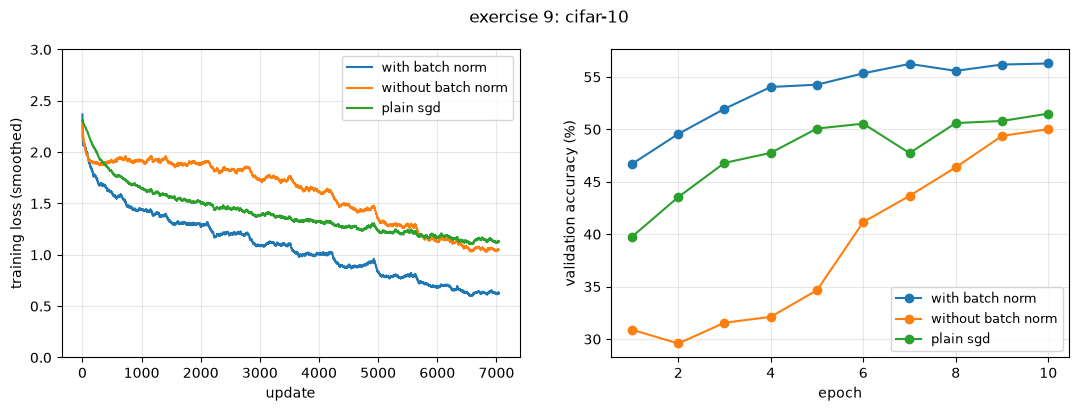

In [ ]:
# Exercise 9 (optional)

# load cifar-10
cifar_train = datasets.CIFAR10(root="data", train=True, download=True)

# split training and validation data
perm = torch.randperm(50000, generator=torch.Generator().manual_seed(42))

# calculate mean and std for each color channel
pixels = torch.from_numpy(cifar_train.data[perm[:45000].numpy()]).float() / 255
mean = pixels.mean(dim=(0, 1, 2))
std = pixels.std(dim=(0, 1, 2))

# normalize and flatten images
def prep_cifar(images):
    images = torch.as_tensor(images).float() / 255
    images = (images - mean) / std
    return images.reshape(len(images), -1)

# prepare training and validation data
X_all = prep_cifar(cifar_train.data)
y_all = torch.tensor(cifar_train.targets)

X_train, y_train = X_all[perm[:45000]], y_all[perm[:45000]]
X_val, y_val = X_all[perm[45000:]], y_all[perm[45000:]]

print("train:", tuple(X_train.shape))
print("validation:", tuple(X_val.shape))

# create results
results = {}

# experiment 1: exercise 7 configuration with batch norm
model = make_model(seed=0,n_in=3072,hidden=(512, 256),batch_norm=True)
optimizer = optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)
loader = make_loader(batch_size=64, n_train=None)

results["with batch norm"] = fit(
    model, optimizer, loader, epochs=10, scheduler=scheduler
)

# experiment 2: same configuration without batch norm
model = make_model(seed=0, n_in=3072, hidden=(512, 256), batch_norm=False)
optimizer = optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)
loader = make_loader(batch_size=64, n_train=None)

results["without batch norm"] = fit(
    model, optimizer, loader, epochs=10, scheduler=scheduler
)

# experiment 3: plain sgd
model = make_model(seed=0, n_in=3072, hidden=(512, 256))
optimizer = optim.SGD(model.parameters(), lr=0.01)
loader = make_loader(batch_size=64, n_train=None)

results["plain sgd"] = fit(
    model, optimizer, loader, epochs=10
)

# print best validation accuracy
for name, hist in results.items():
    print(f"{name}: best validation accuracy = {max(hist['val_acc']):.2f}%")

# plot all three runs
plot_history(results, "exercise 9: cifar-10", ylim=(0, 3))


**Exercise 9: your observations and explanation.** *Write here.*

### observations and explanation

- the model with batch normalization achieves the highest accuracy of 56.28%.
- the model without batch normalization achieves 50.02%.
- plain sgd achieves 51.50%.
- batch normalization improves accuracy by 6.26 percentage points compared with the model without it.
- the training loss decreases during training for all three models.
- cifar-10 is more difficult than mnist because it contains color images and more complex objects.

**conclusion:** the model with batch normalization gives the best result in this experiment. it achieves 56.28% validation accuracy, which is higher than the other two models.

